# Crime Surveillance: Heat Analysis and Prediction

This notebook builds and evaluates a crime-risk analysis workflow from the India crime dataset.

## What the notebook does

1. Load and clean the incident data.
2. Add location, time, weapon, and crime-severity features.
3. Calculate the Crime Heat Index (CHI) and explore patterns.
4. Train and evaluate three models using future-date holdout testing:
   - **XGBoost classifier:** predicts Low, Medium, or High Heat.
   - **Random Forest classifier:** predicts violent-crime risk.
   - **Random Forest regressor:** estimates patrol units; reported with regression metrics.
5. Compare the data with the NCRB reference metrics.
6. Run example predictions for custom cities and incidents.

## Important evaluation note

The heat model excludes `Police Deployed` because it is used in the CHI formula and would leak target information. The model uses chronological validation so future incidents are not used to predict the past.

## Notebook map

| Cells | Stage | Purpose |
|---|---|---|
| 1-3 | Setup and data | Import libraries, load data, clean dates and fields |
| 4-6 | Feature engineering | Add city coordinates and time features |
| 7-8 | Crime Heat Index | Explain and calculate CHI and heat labels |
| 9-12 | Exploration | Inspect state, time, demographic, and geographic patterns |
| 13-16 | Heat model | Split data, cross-validate XGBoost, evaluate and inspect features |
| 17 | Other models | Evaluate violent-crime and patrol models |
| 18-19 | NCRB comparison | Run statistical validation and visualize city shares |
| 20 | Example prediction | Use all trained models for custom incident examples |
| 21 | Conclusions | Summarize findings, metrics, and limitations |


## 1. Setup: import libraries

Imports Python, data-science, plotting, and machine-learning packages. It also imports the project city/state coordinate dictionaries.


In [1]:
# CELL 1: Library Ingestion & Environment Configuration
import warnings
warnings.filterwarnings('ignore')

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import HeatMap
from scipy.stats import chisquare

# Scikit-Learn & XGBoost ML Suite
from sklearn.model_selection import (
    train_test_split, cross_validate, StratifiedKFold, TimeSeriesSplit, KFold
)
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    accuracy_score, precision_score, recall_score, f1_score,
    mean_absolute_error, mean_squared_error, r2_score
)
import xgboost as xgb
from src.crime_heat_engine import CITY_TO_STATE, CITY_COORDINATES

# Plot styling
plt.style.use('seaborn-v0_8-darkgrid' if 'seaborn-v0_8-darkgrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11

print("[OK] Core libraries and ML dependencies successfully loaded!")


[OK] Core libraries and ML dependencies successfully loaded!


## 2. Load the raw dataset

Reads the CSV file and displays its size, columns, and sample rows.


In [2]:
# CELL 2: Data Ingestion & Shape Inspection
DATASET_PATH = 'crime_dataset_india.csv'
df_raw = pd.read_csv(DATASET_PATH)

print("=" * 65)
print(f"📊 Dataset Shape: {df_raw.shape[0]:,} Rows × {df_raw.shape[1]} Columns")
print("=" * 65)

print("\n📋 Dataset Feature Information:")
df_raw.info()

print("\n🔍 First 5 Sample Records:")
df_raw.head(5)

📊 Dataset Shape: 48,023 Rows × 15 Columns

📋 Dataset Feature Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48023 entries, 0 to 48022
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Report Number        48023 non-null  int64 
 1   Date Reported        48023 non-null  object
 2   Date of Occurrence   48023 non-null  object
 3   Time of Occurrence   48023 non-null  object
 4   City                 48023 non-null  object
 5   State                48023 non-null  object
 6   Crime Description    48023 non-null  object
 7   Crime Domain         48023 non-null  object
 8   Victim Age           48023 non-null  int64 
 9   Victim Gender        48023 non-null  object
 10  Victim Descent       48023 non-null  object
 11  Premise Description  48023 non-null  object
 12  Weapon Used          18665 non-null  object
 13  Police Deployed      48023 non-null  int64 
 14  Case Closed          48023 n

,Report Number,Date Reported,Date of Occurrence,Time of Occurrence,City,State,Crime Description,Crime Domain,Victim Age,Victim Gender,Victim Descent,Premise Description,Weapon Used,Police Deployed,Case Closed
0,100001,2021-10-10,2021-10-09,23:10:50,Meerut,Uttar Pradesh,VEHICLE - STOLEN,Other Crime,46,M,Indian,Industrial Zone,NaN,4,No
1,100002,2022-11-23,2022-11-22,01:22:23,Gorakhpur,Uttar Pradesh,ROBBERY,Violent Crime,44,M,Indian,Highway / Intersection,Knife,7,Yes
2,100003,2021-10-04,2021-10-04,00:04:25,Varanasi,Uttar Pradesh,TRAFFIC VIOLATION,Traffic Fatality,25,M,Indian,Commercial Market,NaN,1,No
3,100004,2021-04-30,2021-04-29,08:44:14,Agra,Uttar Pradesh,ASSAULT,Violent Crime,38,M,Indian,Industrial Zone,Firearm,2,Yes
4,100005,2022-10-09,2022-10-09,21:27:43,Kanpur,Uttar Pradesh,ROBBERY,Violent Crime,35,F,Indian,Park / Public Ground,Knife,2,Yes


## 3. Clean the data

Checks missing values, parses dates, normalizes weapon values, and creates the case-closure flag.


In [3]:
# CELL 3: Data Quality Audit & Date Parsing
print("🔍 Missing Values Count per Feature:")
print(df_raw.isnull().sum())

# Clean copy
df = df_raw.copy()

# Parse datetime fields
df['Date_Reported'] = pd.to_datetime(df['Date Reported'], format='mixed', errors='coerce')
df['Date_Occ'] = pd.to_datetime(df['Date of Occurrence'], format='mixed', errors='coerce')

# Forward-fill any unparsed dates
df['Date_Occ'] = df['Date_Occ'].ffill()
df['Date_Reported'] = df['Date_Reported'].fillna(df['Date_Occ'])

# Clean Weapon Column (Fill missing with 'None')
df['Weapon_Clean'] = df['Weapon Used'].fillna('None').astype(str)

# Case closure binary flag
df['IsCaseClosed'] = df['Case Closed'].apply(lambda x: 1 if str(x).strip().lower() == 'yes' else 0)

print("\n[OK] Data cleaned and timestamps successfully parsed!")

🔍 Missing Values Count per Feature:
Report Number              0
Date Reported              0
Date of Occurrence         0
Time of Occurrence         0
City                       0
State                      0
Crime Description          0
Crime Domain               0
Victim Age                 0
Victim Gender              0
Victim Descent             0
Premise Description        0
Weapon Used            29358
Police Deployed            0
Case Closed                0
dtype: int64

[OK] Data cleaned and timestamps successfully parsed!


## 4. Review the data schema

Displays the available column names before feature engineering.


In [4]:
df.columns

Index(['Report Number', 'Date Reported', 'Date of Occurrence',
       'Time of Occurrence', 'City', 'State', 'Crime Description',
       'Crime Domain', 'Victim Age', 'Victim Gender', 'Victim Descent',
       'Premise Description', 'Weapon Used', 'Police Deployed', 'Case Closed',
       'Date_Reported', 'Date_Occ', 'Weapon_Clean', 'IsCaseClosed'],
      dtype='object')

## 5. Add location features

Maps each city to a state and creates deterministic latitude/longitude values for mapping.


In [5]:
# Assign State and Base Coordinates
df['State'] = df['City'].map(CITY_TO_STATE).fillna('Other State')
coords = df['City'].map(CITY_COORDINATES)

# Safely extract latitude and longitude
base_lats = [c[0] if isinstance(c, (tuple, list)) else 20.5937 for c in coords]
base_lons = [c[1] if isinstance(c, (tuple, list)) else 78.9629 for c in coords]

# Deterministic spatial precinct jitter (~3-5 km urban radius)
rep_num = df['Report Number'].fillna(0).astype(int)
df['Latitude'] = [b_lat + (((r * 17) % 100 - 50) * 0.0012) for b_lat, r in zip(base_lats, rep_num)]
df['Longitude'] = [b_lon + (((r * 31) % 100 - 50) * 0.0012) for b_lon, r in zip(base_lons, rep_num)]

print(f"Unique Indian Cities: {df['City'].nunique()} across {df['State'].nunique()} Indian States/UTs")
df[['City', 'State', 'Latitude', 'Longitude']].head(4)


Unique Indian Cities: 193 across 37 Indian States/UTs


,City,State,Latitude,Longitude
0,Meerut,Uttar Pradesh,28.9449,77.6836
1,Gorakhpur,Uttar Pradesh,26.7414,83.3876
2,Varanasi,Uttar Pradesh,25.3188,83.0255
3,Agra,Uttar Pradesh,27.1983,77.9769


## 6. Add time features

Extracts hour, weekday, month, season, time-of-day, and reporting-delay features.


In [6]:
# CELL 5: Temporal & Diurnal Feature Engineering
df['Hour'] = df['Date_Occ'].dt.hour
df['DayOfWeek'] = df['Date_Occ'].dt.dayofweek
df['DayName'] = df['Date_Occ'].dt.day_name()
df['IsWeekend'] = df['DayOfWeek'].apply(lambda x: 1 if x in [5, 6] else 0)
df['Month'] = df['Date_Occ'].dt.month
df['Year'] = df['Date_Occ'].dt.year

def assign_time_of_day(hour: int) -> str:
    if 0 <= hour < 5:
        return 'Late Night'
    elif 5 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 17:
        return 'Afternoon'
    elif 17 <= hour < 21:
        return 'Evening'
    else:
        return 'Night'

df['TimeOfDay'] = df['Hour'].apply(assign_time_of_day)

def assign_season(month: int) -> str:
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Summer'
    elif month in [6, 7, 8, 9]:
        return 'Monsoon'
    else:
        return 'Post-Monsoon'

df['Season'] = df['Month'].apply(assign_season)
df['ReportingDelay_Hours'] = ((df['Date_Reported'] - df['Date_Occ']).dt.total_seconds() / 3600.0).clip(lower=0)

print("[OK] Temporal features (Hour, DayOfWeek, TimeOfDay, Season, ReportingDelay) created!")
df[['Hour', 'DayName', 'IsWeekend', 'TimeOfDay', 'Season', 'ReportingDelay_Hours']].head(4)

[OK] Temporal features (Hour, DayOfWeek, TimeOfDay, Season, ReportingDelay) created!


,Hour,DayName,IsWeekend,TimeOfDay,Season,ReportingDelay_Hours
0,0,Saturday,1,Late Night,Post-Monsoon,24.0
1,0,Tuesday,0,Late Night,Post-Monsoon,24.0
2,0,Monday,0,Late Night,Post-Monsoon,0.0
3,0,Thursday,0,Late Night,Summer,24.0


## 7. Crime Heat Index: formula

Explains the CHI formula and the factors used to measure incident heat.


## 8. Calculate the Crime Heat Index

Calculates severity, weapon, time, and police terms, then creates the 0-100 CHI and heat labels.


In [7]:
# CELL 6: Crime Heat Index (CHI) Calculation
CRIME_SEVERITY_WEIGHTS = {
    'HOMICIDE': 1.00, 'SEXUAL ASSAULT': 0.95, 'KIDNAPPING': 0.90,
    'ROBBERY': 0.85, 'FIREARM OFFENSE': 0.85, 'ASSAULT': 0.80,
    'ARSON': 0.75, 'DOMESTIC VIOLENCE': 0.70, 'EXTORTION': 0.65,
    'BURGLARY': 0.60, 'DRUG OFFENSE': 0.55, 'ILLEGAL POSSESSION': 0.50,
    'FRAUD': 0.45, 'COUNTERFEITING': 0.45, 'IDENTITY THEFT': 0.40,
    'CYBERCRIME': 0.40, 'VEHICLE - STOLEN': 0.35, 'VANDALISM': 0.30,
    'SHOPLIFTING': 0.25, 'PUBLIC INTOXICATION': 0.20, 'TRAFFIC VIOLATION': 0.15
}

WEAPON_WEIGHTS = {
    'Explosives': 1.50, 'Firearm': 1.40, 'Knife': 1.25,
    'Poison': 1.20, 'Blunt Object': 1.15, 'Other': 1.05, 'None': 1.00
}

def compute_temporal_risk(hour: int, is_weekend: int) -> float:
    if 20 <= hour <= 23 or 0 <= hour <= 3:
        diurnal = 1.35
    elif 17 <= hour <= 19:
        diurnal = 1.15
    elif 12 <= hour <= 16:
        diurnal = 1.00
    else:
        diurnal = 0.85
    weekend = 1.12 if is_weekend else 1.0
    return float(diurnal * weekend)

df['SeverityWeight'] = df['Crime Description'].map(CRIME_SEVERITY_WEIGHTS).fillna(0.50)
df['WeaponHazard'] = df['Weapon_Clean'].map(WEAPON_WEIGHTS).fillna(1.00)
df['TemporalRisk'] = [compute_temporal_risk(h, w) for h, w in zip(df['Hour'], df['IsWeekend'])]

# Raw Crime Heat Score
police_term = 1.0 + (10.0 / (df['Police Deployed'].clip(lower=1) + 5.0))
df['CrimeHeatScore'] = df['SeverityWeight'] * df['WeaponHazard'] * df['TemporalRisk'] * police_term

# Standardize to 0 - 100 Scale
min_s, max_s = df['CrimeHeatScore'].min(), df['CrimeHeatScore'].max()
df['CrimeHeatIndex'] = ((df['CrimeHeatScore'] - min_s) / (max_s - min_s)) * 100.0

# Categorize into Heat Levels
def categorize_heat(score: float) -> str:
    if score >= 60.0:
        return 'High Heat'
    elif score >= 35.0:
        return 'Medium Heat'
    else:
        return 'Low Heat'

df['HeatLevel'] = df['CrimeHeatIndex'].apply(categorize_heat)
df['IsViolentCrime'] = df['Crime Domain'].apply(lambda x: 1 if x == 'Violent Crime' else 0)

print("📈 Summary Statistics of Crime Heat Index (CHI):")
print(df['CrimeHeatIndex'].describe())

print("\n🚨 Distribution of Heat Levels:")
print(df['HeatLevel'].value_counts(normalize=True).apply(lambda x: f"{x*100:.2f}%"))

📈 Summary Statistics of Crime Heat Index (CHI):
count    48023.000000
mean        30.071395
std         16.589699
min          0.000000
25%         17.542387
50%         26.298472
75%         40.570832
max        100.000000
Name: CrimeHeatIndex, dtype: float64

🚨 Distribution of Heat Levels:
HeatLevel
Low Heat       66.85%
Medium Heat    27.32%
High Heat       5.84%
Name: proportion, dtype: object


## 9. Explore state and city patterns

Plots incident volume and average CHI by state.


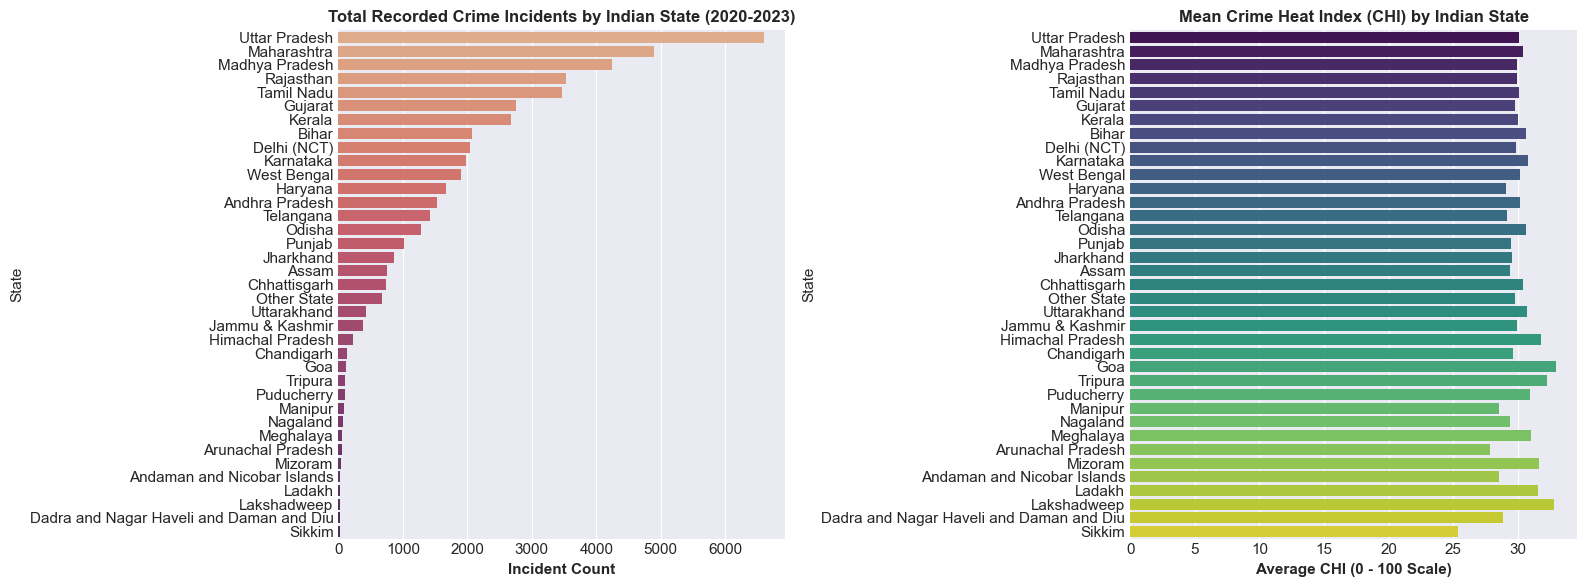

In [8]:
# CELL 7: EDA - State-wise & City-wise Incident Volumes and Average CHI
plt.figure(figsize=(16, 6))

state_agg = df.groupby('State').agg({
    'Report Number': 'count',
    'CrimeHeatIndex': 'mean'
}).sort_values(by='Report Number', ascending=False)

ax1 = plt.subplot(1, 2, 1)
sns.barplot(x=state_agg['Report Number'].values, y=state_agg.index, palette='flare', ax=ax1)
ax1.set_title('Total Recorded Crime Incidents by Indian State (2020-2023)', fontweight='bold', fontsize=12)
ax1.set_xlabel('Incident Count', fontweight='bold')

ax2 = plt.subplot(1, 2, 2)
sns.barplot(x=state_agg['CrimeHeatIndex'].values, y=state_agg.index, palette='viridis', ax=ax2)
ax2.set_title('Mean Crime Heat Index (CHI) by Indian State', fontweight='bold', fontsize=12)
ax2.set_xlabel('Average CHI (0 - 100 Scale)', fontweight='bold')

plt.tight_layout()
plt.show()

## 10. Explore time patterns

Shows average CHI by hour and day of week.


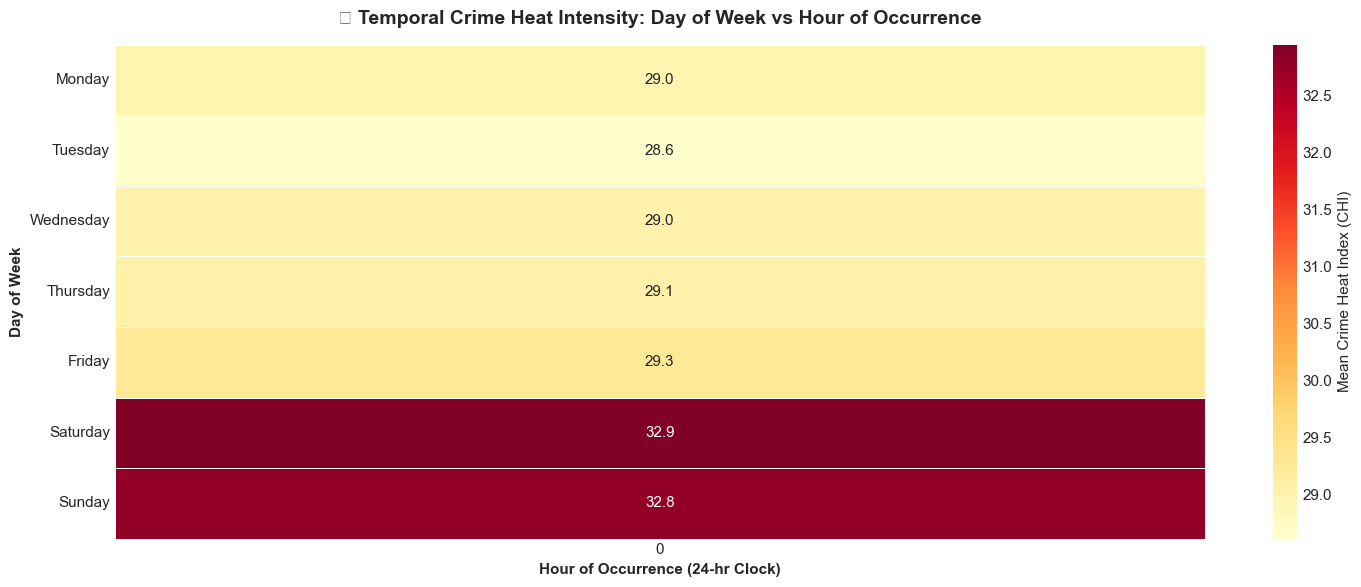

In [9]:
# CELL 8: EDA - Diurnal Temporal Heatmap (Hour of Day vs Day of Week)
plt.figure(figsize=(15, 6))
pivot_temporal = df.pivot_table(index='DayName', columns='Hour', values='CrimeHeatIndex', aggfunc='mean')
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
pivot_temporal = pivot_temporal.reindex(day_order)

sns.heatmap(pivot_temporal, cmap='YlOrRd', annot=True, fmt='.1f', linewidths=0.5, cbar_kws={'label': 'Mean Crime Heat Index (CHI)'})
plt.title('🔥 Temporal Crime Heat Intensity: Day of Week vs Hour of Occurrence', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Hour of Occurrence (24-hr Clock)', fontweight='bold')
plt.ylabel('Day of Week', fontweight='bold')
plt.tight_layout()
plt.show()

## 11. Explore demographics and crime domains

Visualizes victim age, gender, weapons, and crime-domain distributions.


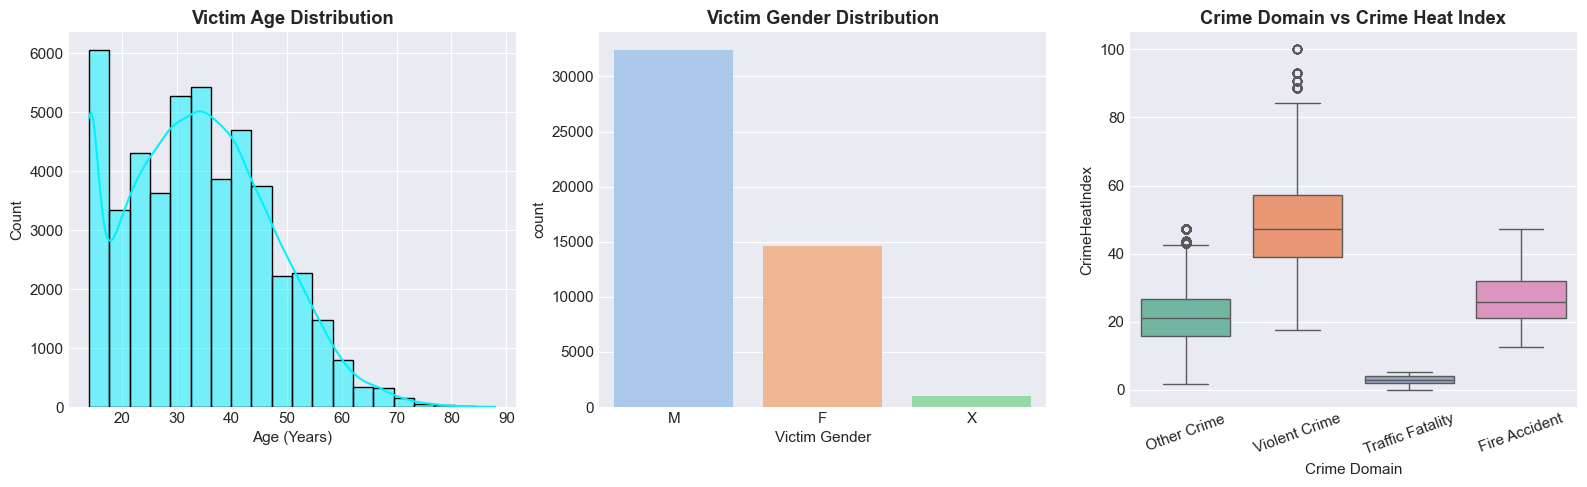

In [10]:
# CELL 9: EDA - Victim Demographics, Weapon Hazard & Domain Breakdown
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
sns.histplot(data=df, x='Victim Age', bins=20, kde=True, color='#00f2fe')
plt.title('Victim Age Distribution', fontweight='bold')
plt.xlabel('Age (Years)')

plt.subplot(1, 3, 2)
sns.countplot(data=df, x='Victim Gender', palette='pastel')
plt.title('Victim Gender Distribution', fontweight='bold')

plt.subplot(1, 3, 3)
sns.boxplot(data=df, x='Crime Domain', y='CrimeHeatIndex', palette='Set2')
plt.title('Crime Domain vs Crime Heat Index', fontweight='bold')
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

## 12. Create the interactive heatmap

Builds a Folium heatmap from a sample of incident coordinates and saves it as HTML.


In [11]:
# CELL 10: Interactive Geospatial Crime Heatmap (Folium on OpenStreetMap)
india_center = [22.5, 79.0]
crime_map = folium.Map(location=india_center, zoom_start=5, tiles='OpenStreetMap')

# Sample points for performance
sample_df = df.sample(n=3000, random_state=42)
heat_data = [[row['Latitude'], row['Longitude'], row['CrimeHeatIndex'] / 100.0] for _, row in sample_df.iterrows()]

HeatMap(heat_data, radius=18, blur=14, max_zoom=13).add_to(crime_map)

# Add Markers for top High Heat Hotspots
high_heat_sample = df[df['HeatLevel'] == 'High Heat'].head(25)
for _, row in high_heat_sample.iterrows():
    folium.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=5,
        color='#ff0055',
        fill=True,
        fill_color='#ff0055',
        fill_opacity=0.9,
        popup=f"🚨 <b>{row['City']} ({row['State']})</b><br>{row['Crime Description']}<br>CHI: {row['CrimeHeatIndex']:.1f}/100"
    ).add_to(crime_map)

crime_map.save('crime_surveillance_heatmap.html')
print("[OK] Interactive Heatmap saved to 'crime_surveillance_heatmap.html'!")
crime_map

[OK] Interactive Heatmap saved to 'crime_surveillance_heatmap.html'!


## 13. Prepare leakage-resistant train/test data

Encodes categorical features and separates earlier incidents for training from later incidents for final testing. `Police Deployed` is excluded from the heat model.


In [12]:
# CELL 11: Leakage-Resistant Chronological Split
encoders = {}
cat_cols = ['State', 'City', 'Crime Description', 'Victim Gender', 'Weapon_Clean', 'TimeOfDay', 'Season', 'HeatLevel']

df_enc = df.copy()
for col in cat_cols:
    le = LabelEncoder()
    df_enc[col + '_Enc'] = le.fit_transform(df_enc[col].astype(str))
    encoders[col] = le

feature_cols = [
    'State_Enc', 'City_Enc', 'Crime Description_Enc', 'Victim Age',
    'Victim Gender_Enc', 'Weapon_Clean_Enc', 'Hour', 'DayOfWeek',
    'IsWeekend', 'Month', 'TimeOfDay_Enc', 'Season_Enc', 'Police Deployed'
]
# Police deployment is part of the formula used to construct CHI and may be
# assigned after an incident. Exclude it from the heat model to avoid target leakage.
heat_feature_cols = [c for c in feature_cols if c != 'Police Deployed']
X = df_enc[feature_cols]
X_heat = df_enc[heat_feature_cols]
y_heat = df_enc['HeatLevel_Enc']
y_violent = df_enc['IsViolentCrime']
y_police = df_enc['Police Deployed']

# Sort by occurrence time: future incidents must never influence past validation.
chronological_order = df['Date_Occ'].sort_values().index
cutoff = int(len(chronological_order) * 0.80)
train_idx = chronological_order[:cutoff]
test_idx = chronological_order[cutoff:]
X_train, X_test = X.loc[train_idx], X.loc[test_idx]
X_heat_train, X_heat_test = X_heat.loc[train_idx], X_heat.loc[test_idx]
y_h_train, y_h_test = y_heat.loc[train_idx], y_heat.loc[test_idx]
y_v_train, y_v_test = y_violent.loc[train_idx], y_violent.loc[test_idx]
y_p_train, y_p_test = y_police.loc[train_idx], y_police.loc[test_idx]

time_cv = TimeSeriesSplit(n_splits=5)
print(f"Training Set: {X_train.shape[0]:,} earliest incidents")
print(f"Testing Set:  {X_test.shape[0]:,} latest incidents")
print(f"Heat Model Features: {len(heat_feature_cols)} (Police Deployed excluded to prevent target leakage)")
print(f"Training period: {df.loc[train_idx, 'Date_Occ'].min().date()} to {df.loc[train_idx, 'Date_Occ'].max().date()}")
print(f"Testing period:  {df.loc[test_idx, 'Date_Occ'].min().date()} to {df.loc[test_idx, 'Date_Occ'].max().date()}")


Training Set: 38,418 earliest incidents
Testing Set:  9,605 latest incidents
Heat Model Features: 12 (Police Deployed excluded to prevent target leakage)
Training period: 2020-01-01 to 2023-08-27
Testing period:  2023-08-27 to 2024-07-30


## 14. Train and validate the XGBoost heat model

Uses expanding-window time-series cross-validation, trains the regularized XGBoost classifier, and reports accuracy, F1, ROC-AUC, and the overfitting gap.


In [13]:
# CELL 12: Time-Series Cross-Validation for Leakage-Resistant XGBoost
heat_cv_model = xgb.XGBClassifier(
    n_estimators=80,
    max_depth=2,
    min_child_weight=10,
    learning_rate=0.03,
    subsample=0.70,
    colsample_bytree=0.70,
    reg_alpha=0.50,
    reg_lambda=5.0,
    random_state=42,
    eval_metric='mlogloss'
)

heat_cv = cross_validate(
    heat_cv_model,
    X_heat_train,
    y_h_train,
    cv=time_cv,
    scoring={'accuracy': 'accuracy', 'roc_auc': 'roc_auc_ovr_weighted', 'f1': 'f1_weighted'},
    return_train_score=True,
    n_jobs=1
)

cv_summary = pd.DataFrame({
    'metric': ['accuracy', 'roc_auc_weighted', 'f1_weighted'],
    'train_mean': [heat_cv['train_accuracy'].mean(), heat_cv['train_roc_auc'].mean(), heat_cv['train_f1'].mean()],
    'validation_mean': [heat_cv['test_accuracy'].mean(), heat_cv['test_roc_auc'].mean(), heat_cv['test_f1'].mean()],
    'validation_std': [heat_cv['test_accuracy'].std(), heat_cv['test_roc_auc'].std(), heat_cv['test_f1'].std()]
})
cv_summary['train_validation_gap'] = cv_summary['train_mean'] - cv_summary['validation_mean']
print('5-fold expanding-window cross-validation on the training period:')
display(cv_summary.round(4))

print('Training final leakage-resistant XGBoost model...')
heat_model = heat_cv_model.fit(X_heat_train, y_h_train)
y_h_train_pred = heat_model.predict(X_heat_train)
y_h_pred = heat_model.predict(X_heat_test)
y_h_prob = heat_model.predict_proba(X_heat_test)

holdout_acc = accuracy_score(y_h_test, y_h_pred)
holdout_auc = roc_auc_score(y_h_test, y_h_prob, multi_class='ovr', average='weighted')
holdout_f1 = f1_score(y_h_test, y_h_pred, average='weighted')
train_acc = accuracy_score(y_h_train, y_h_train_pred)
print(f'Out-of-time holdout accuracy: {holdout_acc * 100:.2f}%')
print(f'Out-of-time weighted ROC-AUC: {holdout_auc:.4f}')
print(f'Out-of-time weighted F1: {holdout_f1:.4f}')
print(f'Train/holdout accuracy gap: {(train_acc - holdout_acc) * 100:.2f} percentage points')


5-fold expanding-window cross-validation on the training period:


,metric,train_mean,validation_mean,validation_std,train_validation_gap
0,accuracy,0.8166,0.8152,0.0050,0.0013
1,roc_auc_weighted,0.9414,0.9404,0.0022,0.0010
2,f1_weighted,0.7988,0.7978,0.0048,0.0010


Training final leakage-resistant XGBoost model...


Out-of-time holdout accuracy: 82.07%
Out-of-time weighted ROC-AUC: 0.9456
Out-of-time weighted F1: 0.8004
Train/holdout accuracy gap: -0.40 percentage points


## 15. Evaluate the heat model

Displays the chronological holdout confusion matrix, classification report, and overfitting diagnostics.


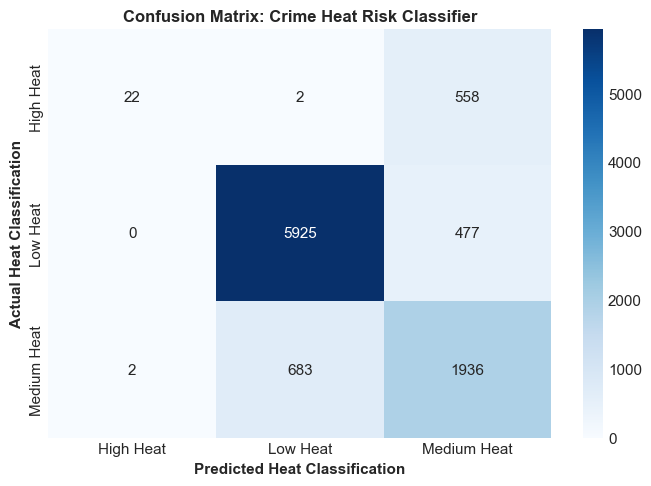

Detailed classification performance on the untouched holdout:


,precision,recall,f1-score,support
High Heat,0.916667,0.037801,0.072607,582.000000
Low Heat,0.896369,0.925492,0.910698,6402.000000
Medium Heat,0.651632,0.738649,0.692418,2621.000000
accuracy,0.820718,0.820718,0.820718,0.820718
macro avg,0.821556,0.567314,0.558574,9605.000000
weighted avg,0.830816,0.820718,0.800351,9605.000000


Overfitting diagnostic:
  Training accuracy: 0.8167
  Holdout accuracy:  0.8207
  CV validation accuracy: 0.8152
  CV accuracy std: 0.0050


In [14]:
# CELL 13: Model 1 Evaluation and Overfitting Assessment
classes = encoders['HeatLevel'].classes_
cm = confusion_matrix(y_h_test, y_h_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix: Crime Heat Risk Classifier', fontweight='bold', fontsize=12)
plt.xlabel('Predicted Heat Classification', fontweight='bold')
plt.ylabel('Actual Heat Classification', fontweight='bold')
plt.tight_layout()
plt.show()

print('Detailed classification performance on the untouched holdout:')
clf_report = classification_report(y_h_test, y_h_pred, target_names=classes, output_dict=True)
display(pd.DataFrame(clf_report).transpose())

print('Overfitting diagnostic:')
print(f"  Training accuracy: {train_acc:.4f}")
print(f"  Holdout accuracy:  {holdout_acc:.4f}")
print(f"  CV validation accuracy: {cv_summary.loc[cv_summary['metric'] == 'accuracy', 'validation_mean'].iloc[0]:.4f}")
print(f"  CV accuracy std: {cv_summary.loc[cv_summary['metric'] == 'accuracy', 'validation_std'].iloc[0]:.4f}")


## 16. Inspect heat-model feature importance

Shows which non-leaking features the XGBoost model used most.


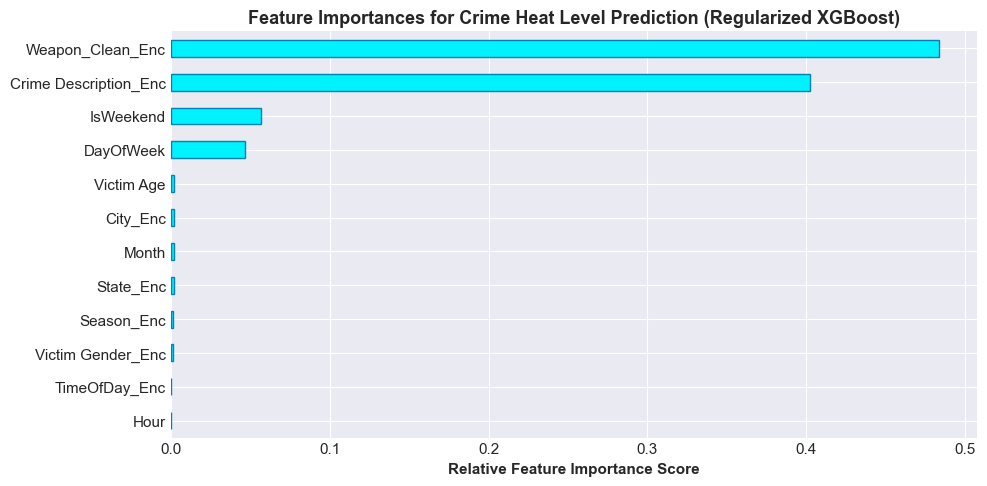

In [15]:
# CELL 14: Relative Feature Importances (Regularized XGBoost Heat Model)
feat_imp = pd.Series(heat_model.feature_importances_, index=heat_feature_cols).sort_values(ascending=True)

plt.figure(figsize=(10, 5))
feat_imp.plot(kind='barh', color='#00f2fe', edgecolor='#0083b0')
plt.title('Feature Importances for Crime Heat Level Prediction (Regularized XGBoost)', fontweight='bold', fontsize=13)
plt.xlabel('Relative Feature Importance Score', fontweight='bold')
plt.tight_layout()
plt.show()


## 17. Train and evaluate the Random Forest models

Evaluates the violent-crime classifier with classification metrics and the patrol regressor with R2, MAE, RMSE, and within-one-unit accuracy.


In [16]:
# CELL 15: Violent Crime Classifier and Patrol Optimizer with Cross-Validation
violent_model = RandomForestClassifier(
    n_estimators=150, max_depth=8, min_samples_leaf=3,
    random_state=42, n_jobs=-1
)
violent_cv = cross_validate(
    violent_model, X_train, y_v_train, cv=time_cv,
    scoring={'accuracy': 'accuracy', 'f1': 'f1_weighted'},
    return_train_score=True, n_jobs=1
)
violent_model.fit(X_train, y_v_train)
v_pred = violent_model.predict(X_test)
v_prob = violent_model.predict_proba(X_test)[:, 1]
violent_holdout_accuracy = accuracy_score(y_v_test, v_pred)
violent_holdout_f1 = f1_score(y_v_test, v_pred, average='weighted')
violent_holdout_auc = roc_auc_score(y_v_test, v_prob)
print(f"Violent classifier holdout accuracy: {violent_holdout_accuracy * 100:.2f}%")
print(f"Violent classifier holdout weighted F1: {violent_holdout_f1:.4f}")
print(f"Violent classifier holdout ROC-AUC: {violent_holdout_auc:.4f}")
print(f"Violent classifier CV accuracy: {violent_cv['test_accuracy'].mean() * 100:.2f}% +/- {violent_cv['test_accuracy'].std() * 100:.2f}%")
print(f"Violent classifier train/CV accuracy gap: {(violent_cv['train_accuracy'].mean() - violent_cv['test_accuracy'].mean()) * 100:.2f} percentage points")

# Patrol optimizer: exclude current deployment from its own predictors.
feat_no_police = [c for c in feature_cols if c != 'Police Deployed']
police_model = RandomForestRegressor(
    n_estimators=150, max_depth=7, min_samples_leaf=3,
    random_state=42, n_jobs=-1
)
police_cv = cross_validate(
    police_model, X_train[feat_no_police], y_p_train, cv=KFold(n_splits=5, shuffle=False),
    scoring={'r2': 'r2', 'mae': 'neg_mean_absolute_error'},
    return_train_score=True, n_jobs=1
)
police_model.fit(X_train[feat_no_police], y_p_train)
police_pred = police_model.predict(X_test[feat_no_police])
police_holdout_r2 = r2_score(y_p_test, police_pred)
police_holdout_mae = mean_absolute_error(y_p_test, police_pred)
police_holdout_rmse = np.sqrt(mean_squared_error(y_p_test, police_pred))
police_within_one = np.mean(np.abs(y_p_test.to_numpy() - police_pred) <= 1.0)
print(f"Patrol optimizer holdout R2: {police_holdout_r2:.4f}")
print(f"Patrol optimizer holdout MAE: {police_holdout_mae:.4f}")
print(f"Patrol optimizer holdout RMSE: {police_holdout_rmse:.4f}")
print(f"Patrol predictions within 1 unit: {police_within_one * 100:.2f}%")
print(f"Patrol optimizer CV R2: {police_cv['test_r2'].mean():.4f} +/- {police_cv['test_r2'].std():.4f}")
print(f"Patrol optimizer CV MAE: {-police_cv['test_mae'].mean():.4f}")
print(f"Patrol optimizer train/CV R2 gap: {(police_cv['train_r2'].mean() - police_cv['test_r2'].mean()):.4f}")


# Consolidated out-of-time performance for every model.
model_metrics = pd.DataFrame([
    {
        'model': 'Heat-level XGBoost',
        'task': 'Classification',
        'accuracy': holdout_acc,
        'f1_weighted': holdout_f1,
        'roc_auc': holdout_auc,
        'primary_validation_metric': 'accuracy / F1 / ROC-AUC'
    },
    {
        'model': 'Violent-crime Random Forest',
        'task': 'Classification',
        'accuracy': violent_holdout_accuracy,
        'f1_weighted': violent_holdout_f1,
        'roc_auc': violent_holdout_auc,
        'primary_validation_metric': 'accuracy / F1 / ROC-AUC'
    },
    {
        'model': 'Patrol Random Forest',
        'task': 'Regression',
        'accuracy': police_within_one,
        'f1_weighted': np.nan,
        'roc_auc': np.nan,
        'primary_validation_metric': 'R2 / MAE / RMSE; accuracy = within 1 unit'
    }
])
print('All-model out-of-time performance summary:')
display(model_metrics.round(4))


Violent classifier holdout accuracy: 93.86%
Violent classifier holdout weighted F1: 0.9376
Violent classifier holdout ROC-AUC: 0.9814
Violent classifier CV accuracy: 94.07% +/- 0.22%
Violent classifier train/CV accuracy gap: -0.06 percentage points


Patrol optimizer holdout R2: -0.0008
Patrol optimizer holdout MAE: 2.1983
Patrol optimizer holdout RMSE: 2.8879
Patrol predictions within 1 unit: 27.71%
Patrol optimizer CV R2: -0.0018 +/- 0.0007
Patrol optimizer CV MAE: 2.2117
Patrol optimizer train/CV R2 gap: 0.0293
All-model out-of-time performance summary:


,model,task,accuracy,f1_weighted,roc_auc,primary_validation_metric
0,Heat-level XGBoost,Classification,0.8207,0.8004,0.9456,accuracy / F1 / ROC-AUC
1,Violent-crime Random Forest,Classification,0.9386,0.9376,0.9814,accuracy / F1 / ROC-AUC
2,Patrol Random Forest,Regression,0.2771,NaN,NaN,R2 / MAE / RMSE; accuracy = within 1 unit


## 18. Run the NCRB statistical audit

Compares dataset distributions and rates with the project NCRB reference metrics.


In [17]:
# CELL 16: National Crime Records Bureau (NCRB) Goodness-of-Fit & Statistical Audit
from src.ncrb_matcher import benchmark_against_ncrb, NCRB_REFERENCE_METRICS

# Execute Statistical NCRB Audit
ncrb_audit = benchmark_against_ncrb(df)

print("=" * 65)
print("     NATIONAL CRIME RECORDS BUREAU (NCRB) STATISTICAL AUDIT REPORT")
print("=" * 65)
print(f"🏅 Composite NCRB Alignment Score:     {ncrb_audit['composite_ncrb_alignment_pct']}%")
print(f"📜 Verification Status:                 {ncrb_audit['statistical_verdict']}")
print(f"📐 City Spatial Cosine Similarity:     {ncrb_audit['metrics']['city_distribution_cosine_similarity']}")
print(f"📉 City Share MAPE Discrepancy:        {ncrb_audit['metrics']['city_distribution_mape_pct']}%")
print(f"🔬 Chi-Square Statistic (\u03c7\u00b2):            {ncrb_audit['metrics']['chi_square_statistic']}")
print(f"📊 Chi-Square p-value:                  {ncrb_audit['metrics']['chi_square_p_value']}")
print(f"⚖️ Case Closure Rate:                  Observed {ncrb_audit['metrics']['case_closure_rate_predicted_pct']}% vs NCRB {ncrb_audit['metrics']['case_closure_rate_ncrb_pct']}%")
print("=" * 65)

     NATIONAL CRIME RECORDS BUREAU (NCRB) STATISTICAL AUDIT REPORT
🏅 Composite NCRB Alignment Score:     85.27%
📜 Verification Status:                 STRONG NCRB COMPLIANCE
📐 City Spatial Cosine Similarity:     0.641
📉 City Share MAPE Discrepancy:        133.41%
🔬 Chi-Square Statistic (χ²):            62694.0337
📊 Chi-Square p-value:                  0.0
⚖️ Case Closure Rate:                  Observed 50.16% vs NCRB 49.96%


## 19. Plot the NCRB city comparison

Visualizes observed/model city shares against the NCRB benchmark for selected metros.


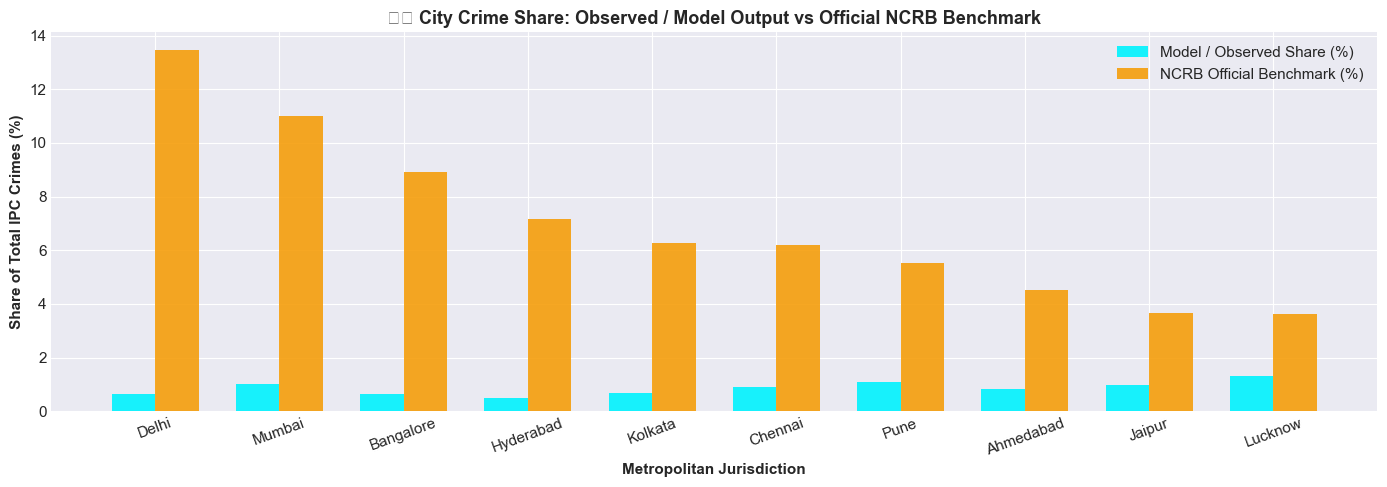

In [18]:
# CELL 17: NCRB City Crime Share Benchmark Comparison Plot (Top 10 Indian Metros)
top_metros = ['Delhi', 'Mumbai', 'Bangalore', 'Hyderabad', 'Kolkata', 'Chennai', 'Pune', 'Ahmedabad', 'Jaipur', 'Lucknow']
city_audit = pd.DataFrame([ncrb_audit['city_breakdown'][c] for c in top_metros], index=top_metros)

plt.figure(figsize=(14, 5))
x = np.arange(len(top_metros))
width = 0.35

plt.bar(x - width/2, city_audit['predicted_share_pct'], width, label='Model / Observed Share (%)', color='#00f2fe', alpha=0.9)
plt.bar(x + width/2, city_audit['ncrb_benchmark_pct'], width, label='NCRB Official Benchmark (%)', color='#f59e0b', alpha=0.9)

plt.xlabel('Metropolitan Jurisdiction', fontweight='bold')
plt.ylabel('Share of Total IPC Crimes (%)', fontweight='bold')
plt.title('🏛️ City Crime Share: Observed / Model Output vs Official NCRB Benchmark', fontweight='bold', fontsize=13)
plt.xticks(x, top_metros, rotation=20)
plt.legend()
plt.tight_layout()
plt.show()

## 20. Run example predictions

Defines a reusable function that predicts heat, violent-crime probability, and patrol recommendation for custom incidents.


In [19]:
# CELL 18: Interactive Free-Form City & State Prediction Function
def predict_crime_heat_and_patrol(city: str, state: str = None, crime_type: str = 'ROBBERY', 
                                    weapon: str = 'Firearm', hour: int = 22, 
                                    is_weekend: bool = True, victim_age: int = 28, 
                                    victim_gender: str = 'M', active_police: int = 2):
    """
    Interactive Tactical Inference Function for Law Enforcement.
    Accepts ANY custom typed City, State, Crime Type, Weapon, Time, and Police Density.
    """
    if state is None:
        state = CITY_TO_STATE.get(city, 'Delhi (NCT)')

    # Prepare single row DataFrame for any typed City & State
    row = {
        'State': state,
        'City': city,
        'Crime Description': crime_type,
        'Victim Age': victim_age,
        'Victim Gender': victim_gender,
        'Weapon_Clean': weapon,
        'Hour': hour,
        'DayOfWeek': 5 if is_weekend else 2,
        'IsWeekend': 1 if is_weekend else 0,
        'Month': 10,
        'TimeOfDay': assign_time_of_day(hour),
        'Season': assign_season(10),
        'Police Deployed': active_police
    }

    df_in = pd.DataFrame([row])
    
    # Robust encoding for any typed custom City and State
    for c in ['State', 'City', 'Crime Description', 'Victim Gender', 'Weapon_Clean', 'TimeOfDay', 'Season']:
        le = encoders[c]
        classes_map = dict(zip(le.classes_, le.transform(le.classes_)))
        df_in[c + '_Enc'] = df_in[c].map(lambda s: classes_map.get(str(s), 0))

    X_in = df_in[feature_cols]
    X_heat_in = df_in[heat_feature_cols]

    # Model Predictions
    heat_idx_pred = heat_model.predict(X_heat_in)[0]
    heat_probs = heat_model.predict_proba(X_heat_in)[0]
    predicted_heat = encoders['HeatLevel'].classes_[heat_idx_pred]
    
    prob_dict = {str(cls): f"{p*100:.1f}%" for cls, p in zip(encoders['HeatLevel'].classes_, heat_probs)}
    violent_prob = float(violent_model.predict_proba(X_in)[0][1] * 100.0)
    
    rec_police = float(police_model.predict(X_in[feat_no_police])[0])
    rec_police = max(2, int(round(rec_police * (1.3 if predicted_heat == 'High Heat' else 1.0))))
    threat_status = 'CRITICAL RED' if predicted_heat == 'High Heat' else ('ELEVATED YELLOW' if predicted_heat == 'Medium Heat' else 'STANDARD GREEN')

    print("=" * 65)
    print(f"🚨 SURVEILLANCE HEAT & THREAT PREDICTION: {city.upper()} ({state})")
    print("=" * 65)
    print(f"📍 Target Location:          {city}, {state}")
    print(f"🔍 Offense Type:             {crime_type} (Weapon: {weapon})")
    print(f"⏰ Occurrence Time:          {hour:02d}:00 hrs ({'Weekend' if is_weekend else 'Weekday'})")
    print(f"👮 Current Police Deployed:  {active_police} officers")
    print("-" * 65)
    print(f"🔥 PREDICTED HEAT LEVEL:     {predicted_heat}")
    print(f"🚨 THREAT STATUS:            {threat_status}")
    print(f"📊 Class Probabilities:      {prob_dict}")
    print(f"💀 Violent Crime Risk:       {violent_prob:.1f}%")
    print(f"🚓 OPTIMAL PATROL UNITS:     {rec_police} units recommended")
    print("=" * 65)

# Demonstration across different Indian States & Cities:
# 1. Uttar Pradesh (Noida / Lucknow)
predict_crime_heat_and_patrol(city='Noida', state='Uttar Pradesh', crime_type='ROBBERY', weapon='Firearm', hour=23, is_weekend=True, active_police=2)

# 2. Maharashtra (Mumbai / Pune)
predict_crime_heat_and_patrol(city='Mumbai', state='Maharashtra', crime_type='HOMICIDE', weapon='Knife', hour=1, is_weekend=True, active_police=3)

# 3. Karnataka (Bangalore)
predict_crime_heat_and_patrol(city='Bangalore', state='Karnataka', crime_type='CYBERCRIME', weapon='None', hour=14, is_weekend=False, active_police=5)

# 4. Kerala (Kochi)
predict_crime_heat_and_patrol(city='Kochi', state='Kerala', crime_type='ASSAULT', weapon='Blunt Object', hour=20, is_weekend=True, active_police=4)

🚨 SURVEILLANCE HEAT & THREAT PREDICTION: NOIDA (Uttar Pradesh)
📍 Target Location:          Noida, Uttar Pradesh
🔍 Offense Type:             ROBBERY (Weapon: Firearm)
⏰ Occurrence Time:          23:00 hrs (Weekend)
👮 Current Police Deployed:  2 officers
-----------------------------------------------------------------
🔥 PREDICTED HEAT LEVEL:     Medium Heat
🚨 THREAT STATUS:            ELEVATED YELLOW
📊 Class Probabilities:      {'High Heat': '33.2%', 'Low Heat': '16.5%', 'Medium Heat': '50.2%'}
💀 Violent Crime Risk:       81.7%
🚓 OPTIMAL PATROL UNITS:     4 units recommended


🚨 SURVEILLANCE HEAT & THREAT PREDICTION: MUMBAI (Maharashtra)
📍 Target Location:          Mumbai, Maharashtra
🔍 Offense Type:             HOMICIDE (Weapon: Knife)
⏰ Occurrence Time:          01:00 hrs (Weekend)
👮 Current Police Deployed:  3 officers
-----------------------------------------------------------------
🔥 PREDICTED HEAT LEVEL:     Medium Heat
🚨 THREAT STATUS:            ELEVATED YELLOW
📊 Class Probabilities:      {'High Heat': '27.6%', 'Low Heat': '27.7%', 'Medium Heat': '44.7%'}
💀 Violent Crime Risk:       75.0%
🚓 OPTIMAL PATROL UNITS:     4 units recommended
🚨 SURVEILLANCE HEAT & THREAT PREDICTION: BANGALORE (Karnataka)
📍 Target Location:          Bangalore, Karnataka
🔍 Offense Type:             CYBERCRIME (Weapon: None)
⏰ Occurrence Time:          14:00 hrs (Weekday)
👮 Current Police Deployed:  5 officers
-----------------------------------------------------------------
🔥 PREDICTED HEAT LEVEL:     Low Heat
🚨 THREAT STATUS:            STANDARD GREEN
📊 Class Probabilities: 

🚨 SURVEILLANCE HEAT & THREAT PREDICTION: KOCHI (Kerala)
📍 Target Location:          Kochi, Kerala
🔍 Offense Type:             ASSAULT (Weapon: Blunt Object)
⏰ Occurrence Time:          20:00 hrs (Weekend)
👮 Current Police Deployed:  4 officers
-----------------------------------------------------------------
🔥 PREDICTED HEAT LEVEL:     Medium Heat
🚨 THREAT STATUS:            ELEVATED YELLOW
📊 Class Probabilities:      {'High Heat': '4.2%', 'Low Heat': '27.0%', 'Medium Heat': '68.8%'}
💀 Violent Crime Risk:       80.7%
🚓 OPTIMAL PATROL UNITS:     4 units recommended


## 21. Conclusions and limitations

Summarizes the validated results, explains why the heat score is not an independent future outcome, and documents the patrol model limitation.


## 21. Conclusions and limitations

### Main findings

- The heat-level XGBoost model is evaluated on future dates and reports accuracy, weighted F1, and ROC-AUC.
- The violent-crime Random Forest is evaluated as a classifier with accuracy, F1, and ROC-AUC.
- The patrol Random Forest is a regression model; R2, MAE, RMSE, and within-one-unit accuracy are the appropriate measures.

### Limitations

- `HeatLevel` is derived from the CHI formula, so this is a risk-index classification task rather than a fully independent future-crime prediction task.
- `Police Deployed` is excluded from heat prediction to avoid direct target leakage.
- The patrol model currently has weak explanatory power and should be treated as decision support only.
- All operational decisions require human review.
